In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score, cross_val_predict, train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline

%matplotlib inline

In [2]:
df = pd.read_csv('module_5_auto.csv')

In [3]:
df.head()

,Unnamed: 0.2,Unnamed: 0,Unnamed: 0.1,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,0,0,0,3,122,alfa-romero,std,two,convertible,rwd,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,1,1,1,3,122,alfa-romero,std,two,convertible,rwd,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,2,2,2,1,122,alfa-romero,std,two,hatchback,rwd,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,3,3,3,2,164,audi,std,four,sedan,fwd,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,4,4,4,2,164,audi,std,four,sedan,4wd,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [4]:
df.drop(columns=["Unnamed: 0.2","Unnamed: 0","Unnamed: 0.1"], axis=1, inplace=True)

In [5]:
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [6]:
df=df._get_numeric_data()
df.head()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
0,3,122,88.6,0.811148,0.890278,48.8,2548,130,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,0,1
1,3,122,88.6,0.811148,0.890278,48.8,2548,130,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,0,1
2,1,122,94.5,0.822681,0.909722,52.4,2823,152,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,0,1
3,2,164,99.8,0.848630,0.919444,54.3,2337,109,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,0,1
4,2,164,99.4,0.848630,0.922222,54.3,2824,136,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,0,1


In [7]:
def DistributionPlot(RedFunction, BlueFunction, RedName, BlueName, Title):
    width = 12
    height = 10

    plt.Figure(figsize=(width, height))

    ax1 = sns.kdeplot(RedFunction, color='r', label=RedName)
    sns.kdeplot(BlueFunction, color='b', label=BlueName, ax=ax1)


    plt.title(Title)
    plt.xlabel('Price (in dollars)')
    plt.ylabel('Proportion of Cars')
    plt.legend()
    plt.show()
    plt.close()

In [8]:
def PollyPlot(x_train, x_test, y_train, y_test, lr, poly_transform):
    plt.figure(figsize=(12, 10))

    xmax = max([x_train.values.max(), x_test.values.max()])
    xmin = min([x_train.values.min(), x_test.values.min()])
    x = np.arange(xmin, xmax, 0.1)

    plt.plot(x_train, y_train, 'ro', label='Training Data')
    plt.plot(x_test, y_test, 'go', label='Test Data')
    x_poly = poly_transform.fit_transform(x.reshape(-1,1))
    plt.plot(x, lr.predict(x_poly),
             label='Predicted Function')

    plt.ylim([-10000, 60000])
    plt.ylabel('Price')
    plt.legend()

In [9]:
y_data = df["price"]

In [10]:
x_data = df.drop(columns='price', axis=1)

In [11]:
x_data.columns

Index(['symboling', 'normalized-losses', 'wheel-base', 'length', 'width',
       'height', 'curb-weight', 'engine-size', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'city-L/100km', 'diesel', 'gas'],
      dtype='object')

In [12]:
#randomly split data into test and train
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.10, random_state=1)

print(f"number of test samples = {x_test.shape[0]}")
print(f"Number of train samples = {x_train.shape[0]}")

number of test samples = 21
Number of train samples = 180


In [13]:
lre = LinearRegression()
lre.fit(x_train[["horsepower"]], y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
lre.score(x_test[["horsepower"]], y_test)

0.36358755750788263

In [15]:
lre.score(x_train[["horsepower"]],y_train)

0.6619724197515104

Sometimes we might not have enough testing data; as a result we may want to perform cross-validation.

In [16]:
Rcross = cross_val_score(lre, x_data[["horsepower"]], y_data, cv=4)

In [17]:
Rcross

array([0.7746232 , 0.51716687, 0.74785353, 0.04839605])

In [18]:
Rcross.mean()

np.float64(0.522009915042119)

In [19]:
Rcross.std()

np.float64(0.291183944475603)

In [20]:
mse = -1 * cross_val_score(lre, x_data[["horsepower"]], y_data, cv=4, scoring='neg_mean_squared_error')

In [21]:
mse.mean()

np.float64(23525298.54198599)

In [22]:
yhta = cross_val_predict(lre, x_data[["horsepower"]], y_data, cv=4)
yhta[0:5]

array([14141.63807508, 14141.63807508, 20814.29423473, 12745.03562306,
       14762.35027598])

In [23]:
for cols in [["horsepower"], ["horsepower", "engine-size"]]:
    r2 = cross_val_score(lre, x_data[cols], y_data, cv=4)
    print(cols, round(r2.mean(), 3), round(r2.std(), 3))

['horsepower'] 0.522 0.291
['horsepower', 'engine-size'] 0.689 0.187


In [24]:
lr = LinearRegression()
lr.fit(x_train[["horsepower","curb-weight","engine-size","highway-mpg"]], y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [25]:
yhat_train = lr.predict(x_train[["horsepower","curb-weight","engine-size","highway-mpg"]])
yhat_train[0:5]

array([ 7426.6731551 , 28323.75090803, 14213.38819709,  4052.34146983,
       34500.19124244])

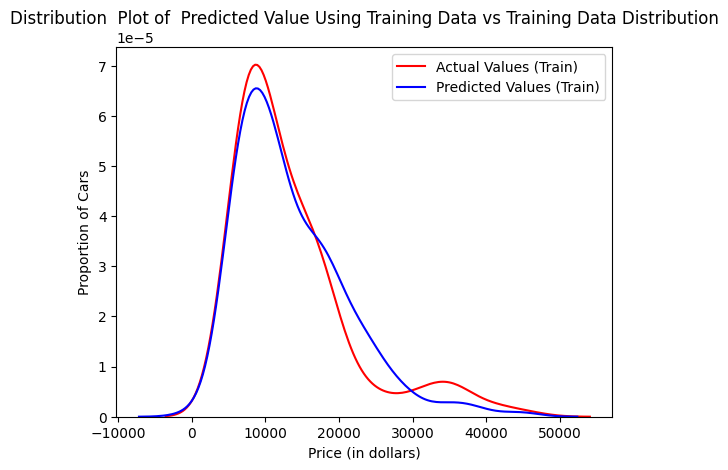

In [26]:
Title = 'Distribution  Plot of  Predicted Value Using Training Data vs Training Data Distribution'
DistributionPlot(y_train, yhat_train, "Actual Values (Train)", "Predicted Values (Train)", Title)

In [27]:
yhat_test = lr.predict(x_test[["horsepower","curb-weight","engine-size","highway-mpg"]])
yhat_test[0:5]

array([11349.35089149,  5884.11059106, 11208.6928275 ,  6641.07786278,
       15565.79920282])

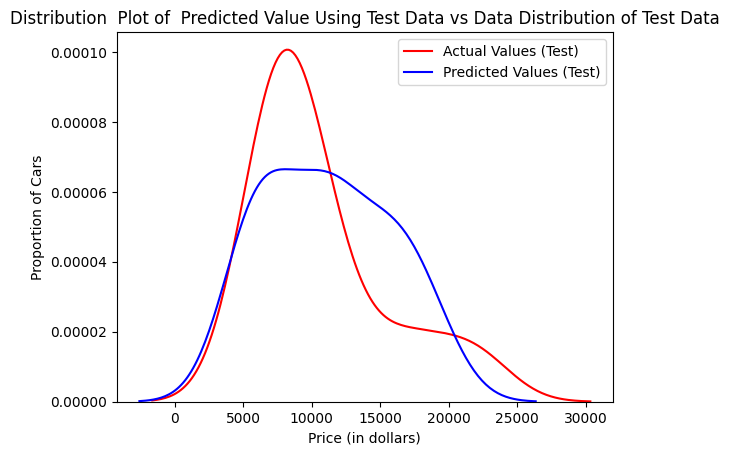

In [28]:
Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
DistributionPlot(y_test,yhat_test,"Actual Values (Test)","Predicted Values (Test)",Title)

In [29]:
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.45, random_state=0)


In [30]:
pr = PolynomialFeatures(degree=5)
x_train_pr = pr.fit_transform(x_train[['horsepower']])
x_test_pr = pr.fit_transform(x_test[['horsepower']])
pr

,degree,5
,interaction_only,False
,include_bias,True
,order,'C'


In [31]:
lm1 = LinearRegression()
lm1.fit(x_train_pr, y_train)
lm1

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [32]:
yhat = lm1.predict(x_test_pr)
yhat[0:5]

array([ 6728.65561887,  7307.98782321, 12213.78770965, 18893.24804015,
       19995.95195136])

In [33]:
print("Predicted values:", yhat[0:4])
print("True values:", y_test[0:4].values)

Predicted values: [ 6728.65561887  7307.98782321 12213.78770965 18893.24804015]
True values: [ 6295. 10698. 13860. 13499.]


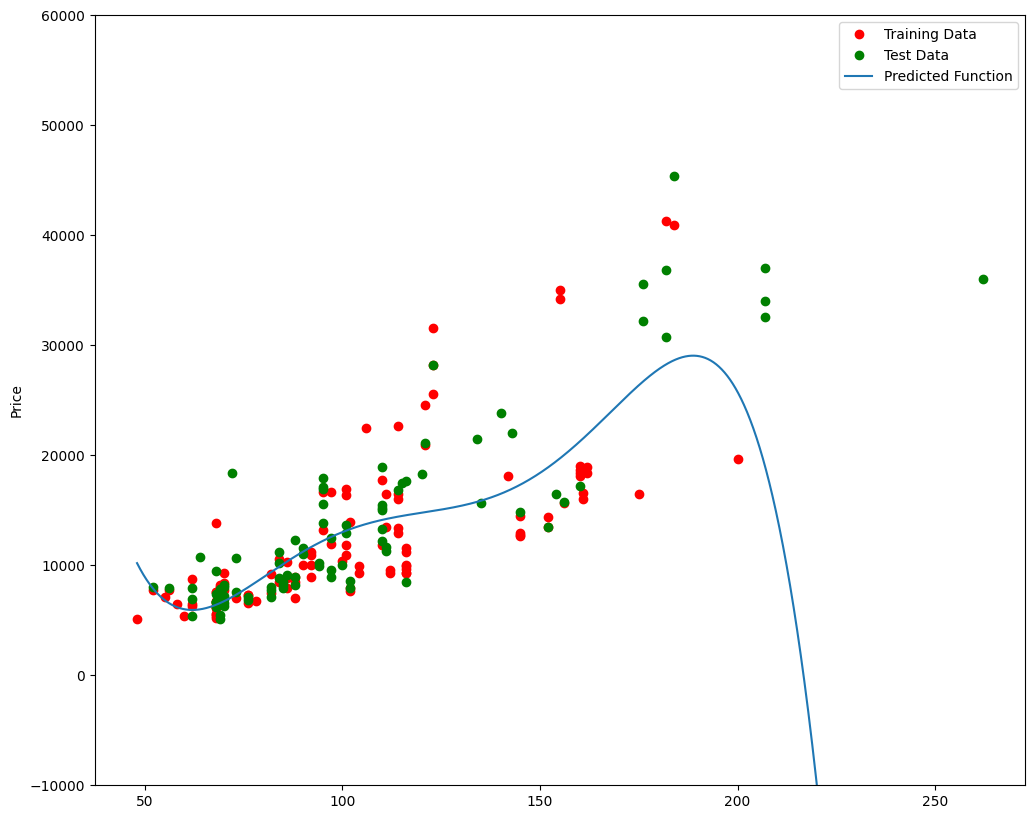

In [34]:
PollyPlot(x_train['horsepower'], x_test['horsepower'], y_train, y_test, lm1,pr)

In [35]:
lm1.score(x_train_pr, y_train)

0.5567716902120254

In [36]:
lm1.score(x_test_pr, y_test)

-29.871340302043684

Text(3, 0.75, 'Maximum R^')

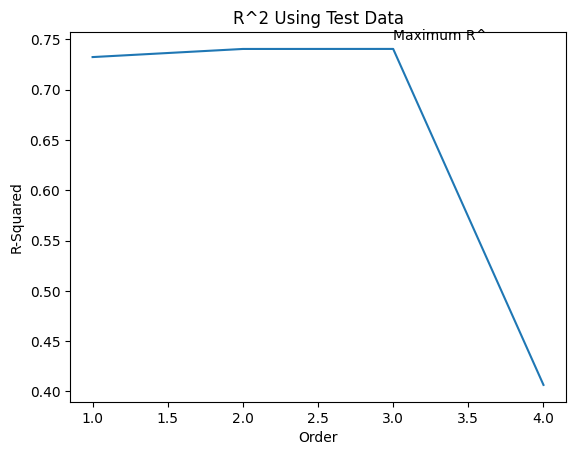

In [37]:
Rsqu_test = []

order = [1,2,3,4]

for n in order:
    pr = PolynomialFeatures(degree=n)
    x_train_pr = pr.fit_transform(x_train[["horsepower"]])
    x_test_pr = pr.fit_transform(x_test[["horsepower"]])
    lr=LinearRegression()
    lr.fit(x_train_pr, y_train)

    Rsqu_test.append(lr.score(x_test_pr, y_test))

plt.plot(order, Rsqu_test)
plt.xlabel('Order')
plt.ylabel('R-Squared')
plt.title("R^2 Using Test Data")
plt.text(3,0.75, 'Maximum R^')

In [38]:
def f(order, test_data):
    x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=test_data, random_state=0)
    pr = PolynomialFeatures(degree=order)
    x_train_pr = pr.fit_transform(x_train[["horsepower"]])

    lm = LinearRegression()
    lm.fit(x_train_pr, y_train)
    PollyPlot(x_train['horsepower'], x_test["horsepower"], y_train, y_test, lm, pr)

interactive(children=(IntSlider(value=3, description='order', max=6), FloatSlider(value=0.45, description='tes…

<function __main__.f(order, test_data)>

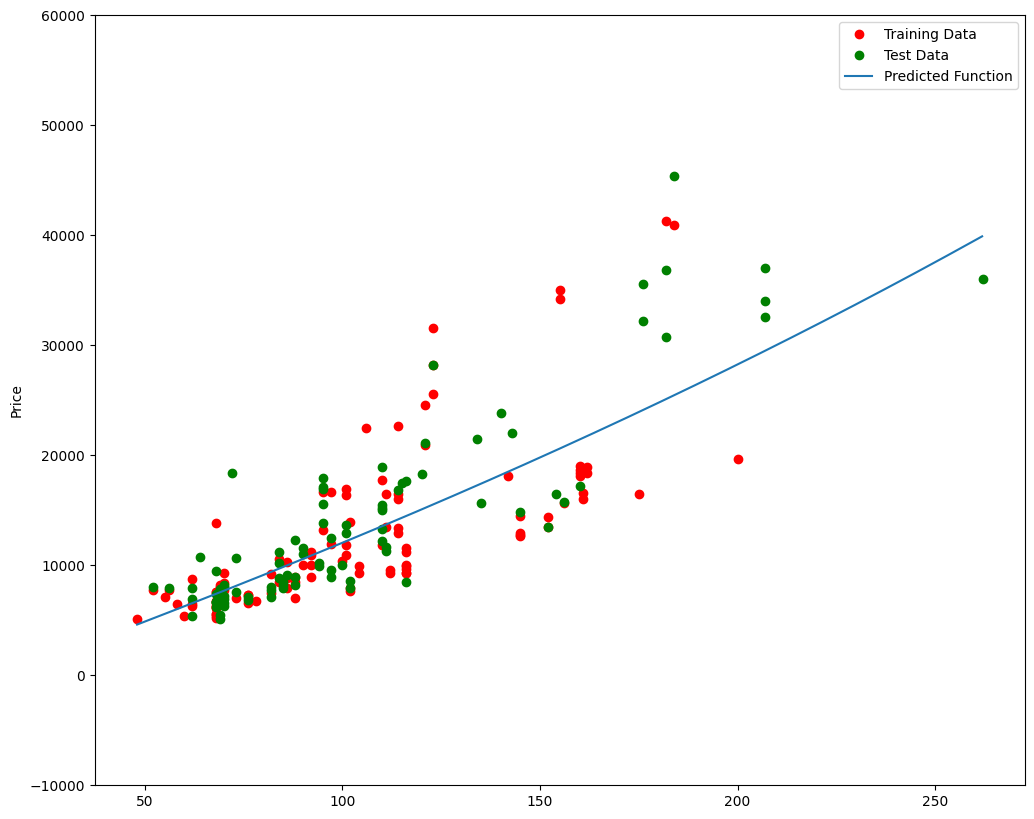

In [39]:
from ipywidgets import interact
interact(f, order=(0,6,1), test_data=(0.05, 0.95,0.05))



In [40]:
pr1 = PolynomialFeatures(degree=2)
x_train_pr1 = pr1.fit_transform(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

x_test_pr1 = pr1.fit_transform(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
poly1 = LinearRegression().fit(x_train_pr1, y_train)
poly1

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


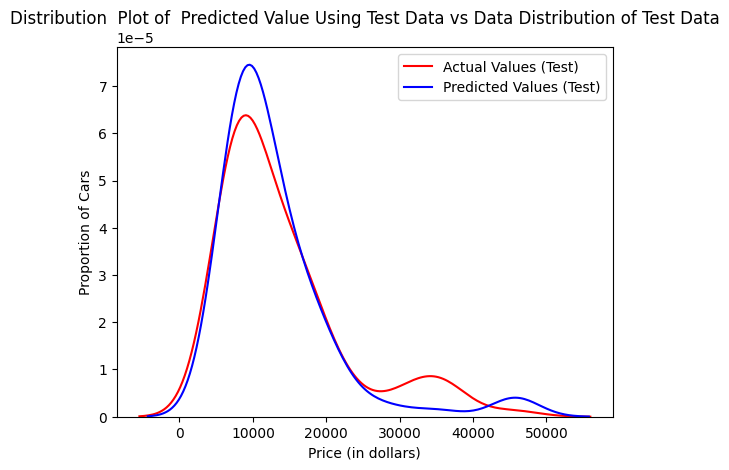

In [41]:
y_hat1 = poly1.predict(x_test_pr1)
Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
DistributionPlot(y_test, y_hat1, "Actual Values (Test)", "Predicted Values (Test)", Title)

In [42]:
#Ridge Regression
pr2=PolynomialFeatures(degree=2)
x_train_pr2=pr2.fit_transform(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])
x_test_pr2=pr2.fit_transform(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])

In [43]:
RidgeModel = Ridge(alpha=1)

In [44]:
RidgeModel.fit(x_train_pr2, y_train)
y_hat_ridge = RidgeModel.predict(x_test_pr2)
print(f"Ridge Predicted Sample values {y_hat_ridge[0:5].round(2)}\nTest Set Values {y_test[0:5].values}")

Ridge Predicted Sample values [ 6570.82  9636.25 20949.92 19403.6  21397.7 ]
Test Set Values [ 6295. 10698. 13860. 13499. 15750.]


In [45]:
from tqdm import tqdm

Rsqu_test = []
Rsqu_train = []
dummy1 = []
Alpha = 10 * np.array(range(0,1000))
pbar = tqdm(Alpha)

for alpha in pbar:
    RidgeModel = Ridge(alpha=alpha)
    RidgeModel.fit(x_train_pr2, y_train)
    test_score, train_score = RidgeModel.score(x_test_pr2, y_test), RidgeModel.score(x_train_pr2, y_train)
    pbar.set_postfix({"Test Score":test_score, "Train Score":train_score})

    Rsqu_test.append(test_score)
    Rsqu_train.append(train_score)

100%|██████████| 1000/1000 [00:02<00:00, 381.83it/s, Test Score=0.564, Train Score=0.859]


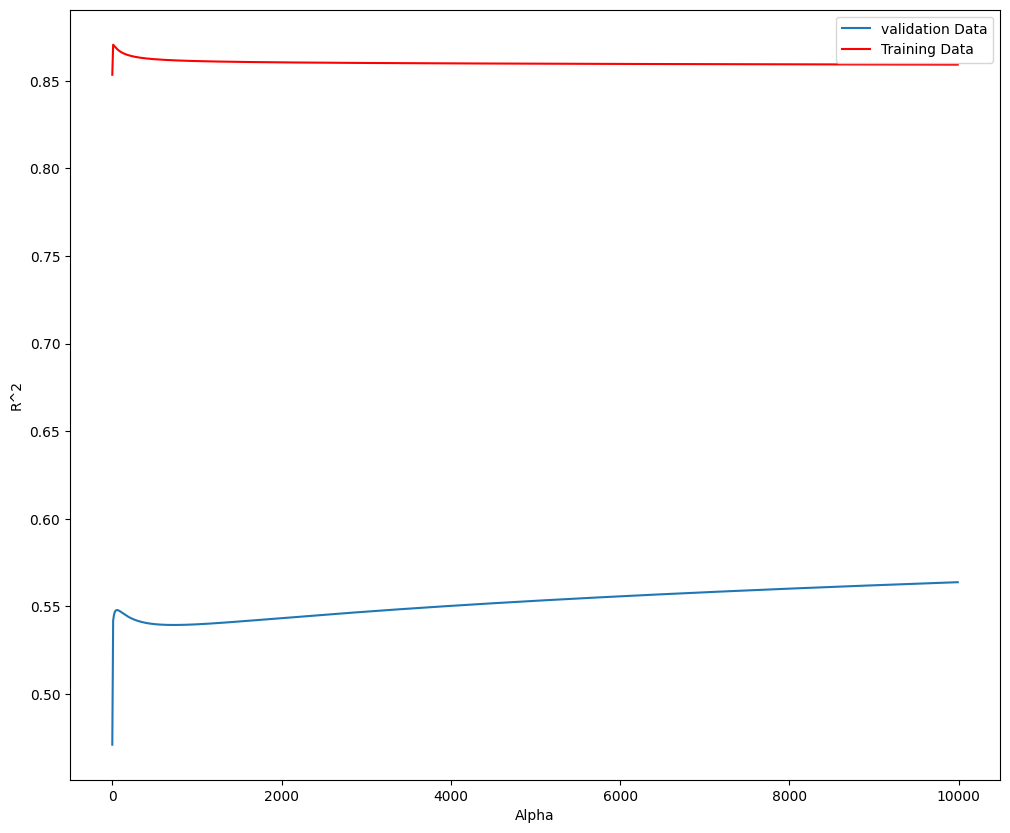

In [46]:
width = 12
height = 10

plt.figure(figsize=(width, height))
plt.plot(Alpha, Rsqu_test, label="validation Data")
plt.plot(Alpha, Rsqu_train, 'r', label="Training Data")

plt.xlabel("Alpha")
plt.ylabel("R^2")
plt.legend()

In [47]:
#Grid Search
parameters1 = [{'alpha':[0.001,0.1,1, 10, 100, 1000, 10000, 100000, 100000]}]
parameters1

[{'alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000, 100000]}]

In [48]:
RR=Ridge()

In [49]:
Grid1 = GridSearchCV(RR, parameters1, cv=4)
Grid1

,estimator,Ridge()
,param_grid,"[{'alpha': [0.001, 0.1, ...]}]"
,scoring,None
,n_jobs,None
,refit,True
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,1.0


In [50]:
Grid1.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)

,estimator,Ridge()
,param_grid,"[{'alpha': [0.001, 0.1, ...]}]"
,scoring,None
,n_jobs,None
,refit,True
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,10000


In [51]:
#The gridsearchcv object finds the best parameter values based on validation data
Grid1.best_estimator_.alpha

10000

In [52]:
Grid1.score(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_test)

0.8411649831036151

In [53]:
pipe1 = Pipeline([
    ('polynomial',PolynomialFeatures()),
    ('scaler',StandardScaler()),
    ('model', Ridge())
])
pipe1

,steps,"[('polynomial', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,degree,2
,interaction_only,False
,include_bias,True
,order,'C'
,copy,True
,with_mean,True
,with_std,True


In [64]:
parameters2 = {
    'model__alpha':[0.001,0.1,1, 10, 100, 1000, 10000, 100000],
    'scaler': [StandardScaler(), 'passthrough'],
    'polynomial__degree':[1,2,3,4]
}

grid2 = GridSearchCV(pipe1, parameters2, cv=4)
grid2.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_train)

/home/masila/.local/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=1.42527e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/masila/.local/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=1.4431e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/masila/.local/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=1.27803e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/masila/.local/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:213: LinAlgWarning: Ill-conditioned matrix (rcond=1.49812e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/masila/.local/lib/python3.10/site-packages/skle

,estimator,"Pipeline(step...l', Ridge())])"
,param_grid,"{'model__alpha': [0.001, 0.1, ...], 'polynomial__degree': [1, 2, ...], 'scaler': [StandardScaler(), 'passthrough']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,degree,2


In [65]:
grid2.best_params_

{'model__alpha': 1, 'polynomial__degree': 2, 'scaler': StandardScaler()}

In [66]:
grid2.best_score_

np.float64(0.6912327964382123)

In [67]:
yhat_grid = grid2.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

In [ ]:
grid2.score(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_test) #Test r squared - validation data

0.7352093194991993

In [69]:
grid2.score(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_train) #Train r squared

0.8409008206744245

In [59]:
cols = ['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge()),
])

parameters = {
    'model__alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000],
    'scaler': [StandardScaler(), 'passthrough'],   # normalize on / off
}

grid = GridSearchCV(pipe, parameters, cv=4)
grid.fit(x_train[cols], y_train)

print(f"{grid.best_params_}, cross-validation score {grid.best_score_}, Test score {grid.score(x_test[cols], y_test)}")       # best alpha and whether scaling won
_              # CV R² of the best combination
   # final check on the test set

{'model__alpha': 10, 'scaler': StandardScaler()}, cross-validation score 0.6148845508891105, Test score 0.7949133572586556


0.8033656377676786

In [62]:
x_data.shape

(201, 18)

In [63]:
x_data.corr().shape

(18, 18)